In [1]:
import os
import random
import json
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import torch
from ultralytics import YOLO

# ================== ПУТИ ==================
PROJECT_ROOT = Path(r"D:\MyWork\Full")
DATA_YAML    = PROJECT_ROOT / "dataset_ready" / "data.yaml"
RUNS_DIR     = PROJECT_ROOT / "runs" / "detect" / "bone_fracture"

print("DATA_YAML :", DATA_YAML, "| exists:", DATA_YAML.exists())
print("RUNS_DIR  :", RUNS_DIR)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\nУстройство: {device}")
if torch.cuda.is_available():
    print(f"GPU : {torch.cuda.get_device_name(0)}")
    print(f"CUDA: {torch.version.cuda}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

DATA_YAML : D:\MyWork\Full\dataset_ready\data.yaml | exists: True
RUNS_DIR  : D:\MyWork\Full\runs\detect\bone_fracture

Устройство: cuda
GPU : NVIDIA GeForce RTX 4060
CUDA: 12.1
VRAM: 8.59 GB


In [2]:
from ultralytics.data.utils import check_det_dataset
from collections import Counter

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

# 1) читаем data.yaml
print("========== data.yaml ==========")
print(DATA_YAML.read_text(encoding="utf-8"))

# 2) что видит YOLO
data = check_det_dataset(str(DATA_YAML))
print("\n========== что видит YOLO ==========")
print("train:", data["train"])
print("val  :", data["val"])
print("nc   :", data["nc"])
print("names:", data["names"])

# 3) считаем позитивы/негативы в каждом сплите
print("\n========== статистика сплитов ==========")
DATA_ROOT = Path(data["path"]) if "path" in data else DATA_YAML.parent
for split in ["train", "val", "test"]:
    if split not in data:
        continue
    root = Path(data[split]).parent.parent   # .../train
    img_dir = root / "images"
    lbl_dir = root / "labels"
    if not img_dir.exists():
        print(f"{split}: нет папки {img_dir}"); continue
    imgs = [p for p in img_dir.glob("*") if p.suffix.lower() in IMG_EXTS]
    n_pos = n_neg = 0
    cls_cnt = Counter()
    for img in imgs:
        lbl = lbl_dir / f"{img.stem}.txt"
        if not lbl.exists():
            continue
        txt = lbl.read_text().strip()
        if txt:
            n_pos += 1
            for line in txt.split("\n"):
                if line.strip():
                    cls_cnt[int(line.split()[0])] += 1
        else:
            n_neg += 1
    print(f"{split:6s}: {len(imgs):4d} изображений | {n_pos:4d} поз. | {n_neg:4d} нег. | "
          f"доля поз. {n_pos/max(len(imgs),1):.1%} | классы {dict(cls_cnt)}")

========== data.yaml ==========
path: D:/MyWork/Full/dataset_ready
train: train/images
val: valid/images
test: test/images

nc: 1
names:
  - Bone-fracture-detection


========== что видит YOLO ==========
train: D:\MyWork\Full\dataset_ready\train\images
val  : D:\MyWork\Full\dataset_ready\valid\images
nc   : 1
names: {0: 'Bone-fracture-detection'}

========== статистика сплитов ==========
train: нет папки D:\MyWork\Full\dataset_ready\images
val: нет папки D:\MyWork\Full\dataset_ready\images
test: нет папки D:\MyWork\Full\dataset_ready\images


Позитивов в train: 136 | Негативов: 91


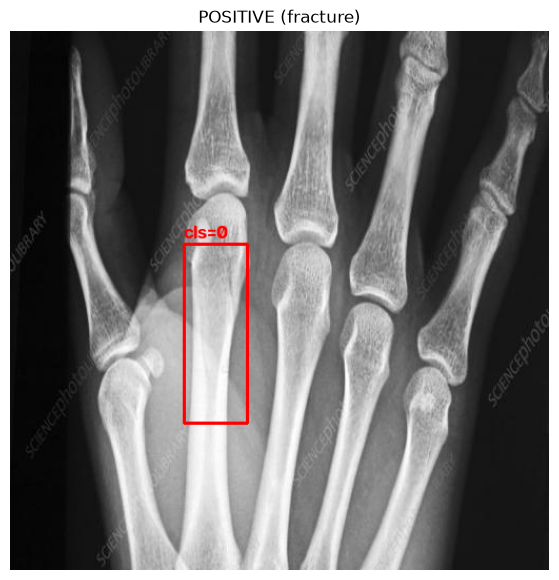

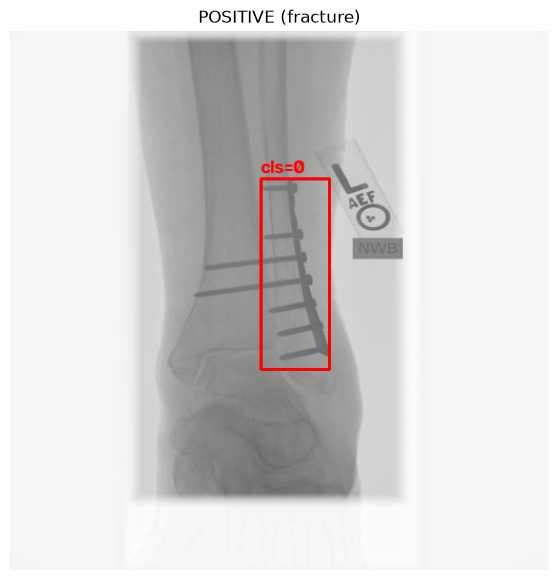

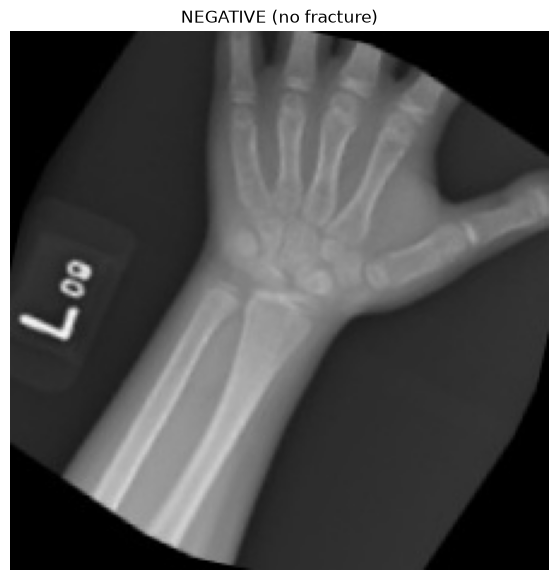

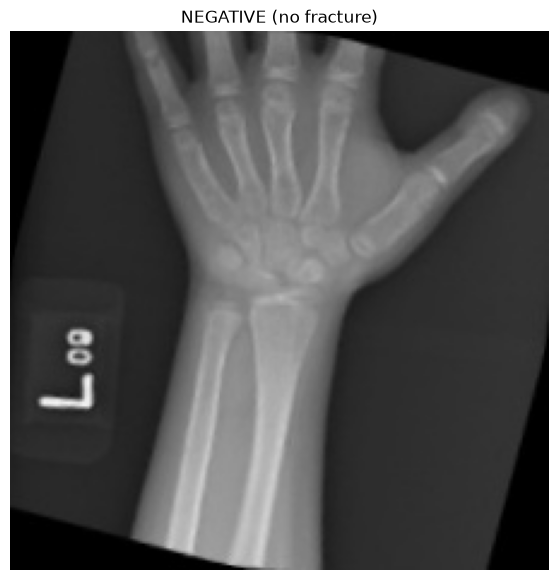

In [3]:
def show_sample(img_path, lbl_path):
    img = cv2.imread(str(img_path))
    if img is None:
        return
    h, w = img.shape[:2]
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    content = lbl_path.read_text().strip() if lbl_path.exists() else ""
    if content:
        for line in content.split("\n"):
            cls, cx, cy, bw, bh = map(float, line.split())
            x1 = int((cx - bw/2) * w); y1 = int((cy - bh/2) * h)
            x2 = int((cx + bw/2) * w); y2 = int((cy + bh/2) * h)
            cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)
            cv2.putText(img, f"cls={int(cls)}", (x1, max(15, y1-5)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)
        title = "POSITIVE (fracture)"
    else:
        title = "NEGATIVE (no fracture)"
    plt.figure(figsize=(7, 7)); plt.imshow(img); plt.axis("off"); plt.title(title); plt.show()

train_root = Path(data["train"]).parent
train_img_dir = train_root / "images"
train_lbl_dir = train_root / "labels"

pos = [p for p in train_img_dir.iterdir()
       if p.suffix.lower() in IMG_EXTS and (train_lbl_dir / f"{p.stem}.txt").read_text().strip()]
neg = [p for p in train_img_dir.iterdir()
       if p.suffix.lower() in IMG_EXTS and not (train_lbl_dir / f"{p.stem}.txt").read_text().strip()]

print(f"Позитивов в train: {len(pos)} | Негативов: {len(neg)}")
random.seed(42)
for p in random.sample(pos, min(2, len(pos))):
    show_sample(p, train_lbl_dir / f"{p.stem}.txt")
for p in random.sample(neg, min(2, len(neg))):
    show_sample(p, train_lbl_dir / f"{p.stem}.txt")

In [4]:
RUN_NAME = f"run_{datetime.now():%Y%m%d_%H%M%S}"

model = YOLO("yolov8s.pt")   # предобученная COCO

results = model.train(
    data=str(DATA_YAML),
    epochs=200,
    imgsz=640,
    batch=8,
    device=0,
    workers=4,
    patience=50,
    cache=True,
    optimizer="AdamW",
    lr0=0.001,
    lrf=0.01,
    cos_lr=True,
    warmup_epochs=3,
    weight_decay=0.0005,
    dropout=0.05,
    # аугментации под рентген:
    degrees=15.0,
    translate=0.15,
    scale=0.7,
    shear=3.0,
    fliplr=0.5,
    flipud=0.0,
    mosaic=1.0,
    mixup=0.15,
    hsv_h=0.010, hsv_s=0.3, hsv_v=0.3,
    # вывод:
    project=str(RUNS_DIR),
    name=RUN_NAME,
    exist_ok=False,
    plots=True,
    save_period=25,
    val=True,
)

BEST_WEIGHTS = RUNS_DIR / RUN_NAME / "weights" / "best.pt"
LAST_WEIGHTS = RUNS_DIR / RUN_NAME / "weights" / "last.pt"
print("Best:", BEST_WEIGHTS, "| exists:", BEST_WEIGHTS.exists())
print("Last:", LAST_WEIGHTS, "| exists:", LAST_WEIGHTS.exists())

New https://pypi.org/project/ultralytics/8.4.177 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.176  Python-3.12.0 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4060, 8188MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=D:\MyWork\Full\dataset_ready\data.yaml, degrees=15.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.05, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.3, hsv_v=0.3, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.15, mode=train, model

МЕТРИКА 0,504

## Увеличим картинку 

In [6]:
PREV_BEST = RUNS_DIR / "run_20261013_184419" / "weights" / "best.pt"

Ultralytics 8.4.176  Python-3.12.0 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4060, 8188MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 368.2±146.0 MB/s, size: 14.6 KB)
val: Scanning D:\MyWork\Full\dataset_ready\valid\labels.cache... 66 images, 27 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 66/66  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 4.1it/s 2.2s<0.2s
                   all         66         55      0.684      0.473      0.479      0.193
Speed: 1.1ms preprocess, 5.7ms inference, 0.0ms loss, 0.4ms postprocess per image
Ultralytics 8.4.176  Python-3.12.0 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4060, 8188MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 491.4±185.7 MB/s, size: 18.7 KB)
val: Scanning D:\MyWork\Full\dataset_ready\valid

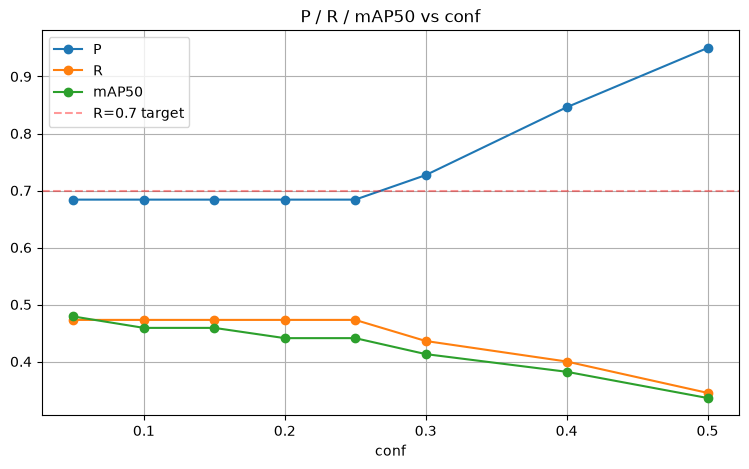

In [7]:
best_model = YOLO(str(PREV_BEST))

confs = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]
rows = []

for c in confs:
    m = best_model.val(
        data=str(DATA_YAML),
        split="val",
        imgsz=640,          # пока валидируем на 640 (модель училась на 640)
        batch=8,
        conf=c,
        iou=0.5,
        device=0,
        verbose=False,
        plots=False,
    )
    rows.append({
        "conf": c,
        "P": round(m.box.mp, 3),
        "R": round(m.box.mr, 3),
        "mAP50": round(m.box.map50, 3),
        "mAP50-95": round(m.box.map, 3),
    })

df_conf = pd.DataFrame(rows)
print(df_conf.to_string(index=False))

# визуализация
df_conf.plot(x="conf", y=["P", "R", "mAP50"], marker="o", figsize=(9, 5), grid=True)
plt.title("P / R / mAP50 vs conf")
plt.axhline(0.7, color="red", linestyle="--", alpha=0.4, label="R=0.7 target")
plt.legend()
plt.show()

In [8]:
model = YOLO("yolov8s.pt")

results = model.train(
    data=str(DATA_YAML),

    # ---- ключевые изменения ----
    imgsz=960,           # было 640 — теперь модель видит мелкие трещины
    batch=4,             # было 8 — уменьшили из-за возросшего imgsz

    # ---- обучение ----
    epochs=200,
    patience=50,
    device=0,
    workers=4,
    cache=True,          # кэш в RAM — быстрее
    optimizer="AdamW",
    lr0=0.001,
    lrf=0.01,
    cos_lr=True,
    warmup_epochs=3,
    weight_decay=0.0005,
    dropout=0.05,

    # ---- аугментации под рентген ----
    degrees=15.0,
    translate=0.15,
    scale=0.7,
    shear=3.0,
    fliplr=0.5,
    flipud=0.0,          # для рентгена верх/низ важен
    mosaic=1.0,
    mixup=0.15,
    hsv_h=0.010,
    hsv_s=0.3,
    hsv_v=0.3,

    # ---- вывод ----
    project=str(RUNS_DIR),
    name=RUN_NAME,
    exist_ok=False,
    plots=True,
    save_period=25,
    val=True,
)

BEST_960 = RUNS_DIR / RUN_NAME / "weights" / "best.pt"
LAST_960 = RUNS_DIR / RUN_NAME / "weights" / "last.pt"
print("Best:", BEST_960, "| exists:", BEST_960.exists())
print("Last:", LAST_960, "| exists:", LAST_960.exists())

New https://pypi.org/project/ultralytics/8.4.177 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.176  Python-3.12.0 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4060, 8188MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=D:\MyWork\Full\dataset_ready\data.yaml, degrees=15.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.05, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.3, hsv_v=0.3, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.15, mode=train, model